# Smart MCQ Solver — Semantic Similarity & Transformer-Based Answer Ranking

**DL / GenAI Project · Student ID: 24f1002692**

An end-to-end pipeline that ranks the top-3 most probable answers for multiple-choice 
questions, evaluated with MAP@3. Progresses from classical NLP baselines (TF-IDF, Word2Vec) 
to pretrained transformer approaches (BERT/RoBERTa embeddings, Sentence-Transformers, 
zero-shot NLI classification, and generative SLM prompting).

## Import Libraries

In [1]:
import os, re, io, sys, string, warnings, logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import kagglehub, nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

import torch
import torch.nn.functional as F

from datasets import load_dataset
from tqdm import tqdm
from gensim.models import Word2Vec

from transformers import (
    AutoTokenizer,
    AutoModel,
    AutoModelForSeq2SeqLM,
    pipeline,
)
from sentence_transformers import SentenceTransformer, util
from transformers import pipeline as hf_pipeline

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import cosine_similarity
print("-------- Libraries imported -------")

-------- Libraries imported -------


In [2]:
# HuggingFace Hub download bars + auth warning
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

from huggingface_hub.utils import disable_progress_bars
disable_progress_bars()

# datasets library (.map(), load_dataset) progress bars
from datasets.utils.logging import disable_progress_bar as ds_disable_progress_bar
ds_disable_progress_bar()

# transformers logging (loading model/config messages)
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()

# general warnings
warnings.filterwarnings("ignore")
logging.getLogger("transformers").setLevel(logging.ERROR)
logging.getLogger("datasets").setLevel(logging.ERROR)

In [3]:
warnings.filterwarnings('ignore')

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/jjinho/wikipedia-2023-07-faiss-index/wikipedia_202307.index
/kaggle/input/datasets/jjinho/wikipedia-20230701/x.parquet
/kaggle/input/datasets/jjinho/wikipedia-20230701/h.parquet
/kaggle/input/datasets/jjinho/wikipedia-20230701/w.parquet
/kaggle/input/datasets/jjinho/wikipedia-20230701/g.parquet
/kaggle/input/datasets/jjinho/wikipedia-20230701/a.parquet
/kaggle/input/datasets/jjinho/wikipedia-20230701/y.parquet
/kaggle/input/datasets/jjinho/wikipedia-20230701/l.parquet
/kaggle/input/datasets/jjinho/wikipedia-20230701/n.parquet
/kaggle/input/datasets/jjinho/wikipedia-20230701/i.parquet
/kaggle/input/datasets/jjinho/wikipedia-20230701/number.parquet
/kaggle/input/datasets/jjinho/wikipedia-20230701/j.parquet
/kaggle/input/datasets/jjinho/wikipedia-20230701/m.parquet
/kaggle/input/datasets/jjinho/wikipedia-20230701/b.parquet
/kaggle/input/datasets/jjinho/wikipedia-20230701/r.parquet
/kaggle/input/datasets/jjinho/wikipedia-20230701/v.parquet
/kaggle/input/datasets/jjin

## Load Data

In [4]:
sample_submission = pd.read_csv(
    "/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv"
)
train_dataset = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")
test_dataset = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv")

if 'id' in train_dataset.columns:
    train_dataset = train_dataset.drop(columns=['id'])

print('Train shape:', train_dataset.shape)   # (2000, 7)
print('Test shape :', test_dataset.shape)    # (500, 6)
print('Columns    :', train_dataset.columns.tolist())
print('Answer dist:', train_dataset['answer'].value_counts().to_dict())

Train shape: (2000, 7)
Test shape : (500, 7)
Columns    : ['prompt', 'A', 'B', 'C', 'D', 'E', 'answer']
Answer dist: {'B': 490, 'C': 459, 'A': 369, 'D': 358, 'E': 324}


## Exploratory Data Analysis

  DATASET OVERVIEW
  Rows                  : 2,000
  Nulls                 : 0
  Duplicate prompts     : 242
  Unique option texts   : 1,584 / 10,000

  Answer distribution:
    A  369  (18.4%)
    B  490  (24.5%)
    C  459  (22.9%)
    D  358  (17.9%)
    E  324  (16.2%)

  Correct option avg len    : 181.9 chars
  Wrong  option avg len     : 160.7 chars
  longest option is correct : 40.6% of the time
  Avg total tokens/question : 236  (max 651)


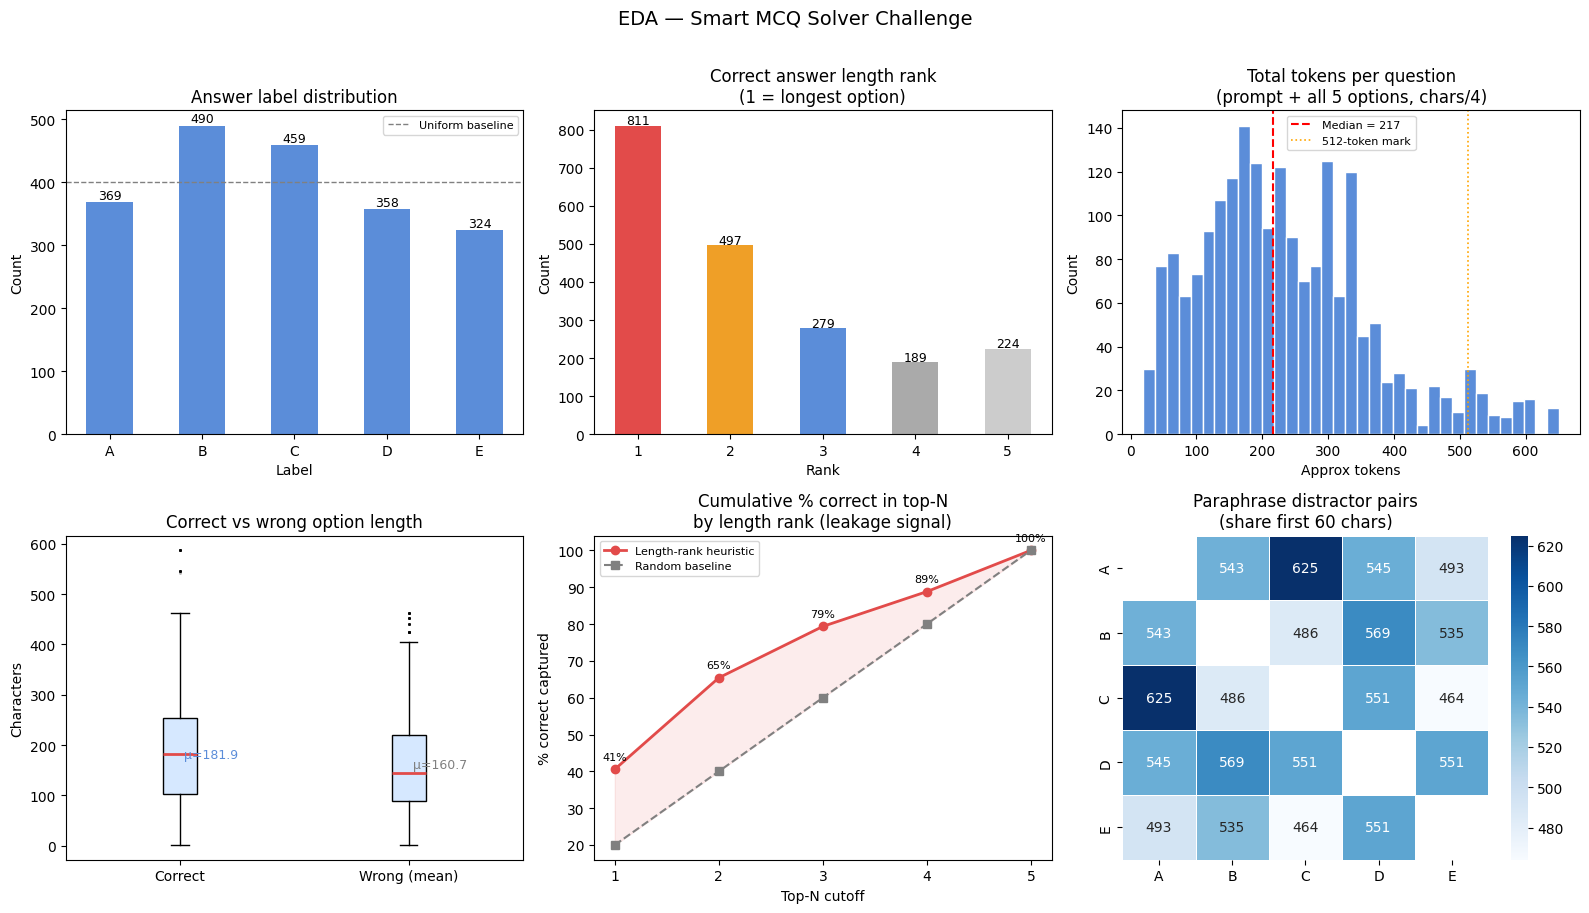

✓ EDA complete.


In [5]:
# ===========================================================
# EDA — Smart MCQ Solver  |  DL / GenAI notebook
# ===========================================================

OPTIONS = ["A", "B", "C", "D", "E"]
train = train_dataset.copy()

# -----------------------------------------------------------
# feature engineering
# -----------------------------------------------------------
for c in OPTIONS:
    train[f"{c}_len"] = train[c].str.len()

train["prompt_tokens"] = (train["prompt"].str.len() / 4).round().astype(int)  # 4 is approximate token length in english language normally
train["total_tokens"]  = (
    train["prompt_tokens"]
    + sum((train[f"{c}_len"] / 4).round().astype(int) for c in OPTIONS)
)

def correct_option_rank_by_length(row):
    lengths = {c: row[f"{c}_len"] for c in OPTIONS}
    return sorted(lengths, key=lengths.get, reverse=True).index(row["answer"]) + 1

train["correct_option_rank_by_length"] = train.apply(correct_option_rank_by_length, axis=1)
train["correct_option_len"] = train.apply(lambda r: r[f"{r['answer']}_len"], axis=1)
train["mean_wrong_len"]     = train.apply(
    lambda r: np.mean([r[f"{c}_len"] for c in OPTIONS if c != r["answer"]]), axis=1
)

# -----------------------------------------------------------
# overview print
# -----------------------------------------------------------
print("=" * 52)
print("  DATASET OVERVIEW")
print("=" * 52)
print(f"  Rows                  : {len(train):,}")
print(f"  Nulls                 : {train.isnull().sum().sum()}")
print(f"  Duplicate prompts     : {train.duplicated('prompt').sum()}")
print(f"  Unique option texts   : {pd.concat([train[c] for c in OPTIONS]).nunique():,} / {len(train)*5:,}")
print()
print("  Answer distribution:")
for label, cnt in train["answer"].value_counts().reindex(OPTIONS).items():
    print(f"    {label}  {cnt}  ({cnt/len(train)*100:.1f}%)")
print()
print(f"  Correct option avg len    : {train['correct_option_len'].mean():.1f} chars")
print(f"  Wrong  option avg len     : {train['mean_wrong_len'].mean():.1f} chars")
print(f"  longest option is correct : {(train['correct_option_rank_by_length']==1).mean()*100:.1f}% of the time")
print(f"  Avg total tokens/question : {train['total_tokens'].mean():.0f}  (max {train['total_tokens'].max()})")
print("=" * 52)

# -----------------------------------------------------------
# figures
# -----------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle("EDA — Smart MCQ Solver Challenge", fontsize=14, y=1.01)

# 1. answer label distribution
ans_counts = train["answer"].value_counts().reindex(OPTIONS)
axes[0, 0].bar(OPTIONS, ans_counts.values, color="#5B8DD9", width=0.5)
axes[0, 0].axhline(len(train) / 5, color="gray", lw=1, linestyle="--", label="Uniform baseline")
axes[0, 0].set_title("Answer label distribution")
axes[0, 0].set_xlabel("Label")
axes[0, 0].set_ylabel("Count")
axes[0, 0].legend(fontsize=8)
for i, v in enumerate(ans_counts.values):
    axes[0, 0].text(i, v + 5, str(v), ha="center", fontsize=9)

# 2. correct answer length rank
rank_counts = train["correct_option_rank_by_length"].value_counts().sort_index()
axes[0, 1].bar(rank_counts.index, rank_counts.values,
               color=["#E24B4A", "#EF9F27", "#5B8DD9", "#AAAAAA", "#CCCCCC"], width=0.5)
axes[0, 1].set_title("Correct answer length rank\n(1 = longest option)")
axes[0, 1].set_xlabel("Rank")
axes[0, 1].set_ylabel("Count")
for x, v in zip(rank_counts.index, rank_counts.values):
    axes[0, 1].text(x, v + 4, str(v), ha="center", fontsize=9)

# 3. total tokens per question
axes[0, 2].hist(train["total_tokens"], bins=35, color="#5B8DD9", edgecolor="white", lw=0.4)
axes[0, 2].axvline(train["total_tokens"].median(), color="red", lw=1.5,
                   linestyle="--", label=f"Median = {train['total_tokens'].median():.0f}")
axes[0, 2].axvline(512, color="orange", lw=1.2, linestyle=":", label="512-token mark")
axes[0, 2].set_title("Total tokens per question\n(prompt + all 5 options, chars/4)")
axes[0, 2].set_xlabel("Approx tokens")
axes[0, 2].set_ylabel("Count")
axes[0, 2].legend(fontsize=8)

# 4. correct vs wrong option length boxplot
axes[1, 0].boxplot(
    [train["correct_option_len"].values, train["mean_wrong_len"].values],
    labels=["Correct", "Wrong (mean)"],
    patch_artist=True,
    boxprops=dict(facecolor="#D6E8FF"),
    medianprops=dict(color="#E24B4A", linewidth=2),
    flierprops=dict(marker=".", markersize=2, alpha=0.3),
)
axes[1, 0].set_title("Correct vs wrong option length")
axes[1, 0].set_ylabel("Characters")
for x, col, val in [(1, "#5B8DD9", train["correct_option_len"].mean()),
                    (2, "gray",    train["mean_wrong_len"].mean())]:
    axes[1, 0].text(x, val, f" μ={val:.1f}", va="center", fontsize=9, color=col)

# 5. cumulative top-N by length rank vs random
cumulative      = [(train["correct_option_rank_by_length"] <= n).mean() * 100 for n in range(1, 6)]
random_baseline = [n / 5 * 100 for n in range(1, 6)]
axes[1, 1].plot(range(1, 6), cumulative, "o-", color="#E24B4A", lw=2, label="Length-rank heuristic")
axes[1, 1].plot(range(1, 6), random_baseline, "s--", color="gray", lw=1.5, label="Random baseline")
axes[1, 1].fill_between(range(1, 6), random_baseline, cumulative, alpha=0.1, color="#E24B4A")
axes[1, 1].set_title("Cumulative % correct in top-N\nby length rank (leakage signal)")
axes[1, 1].set_xlabel("Top-N cutoff")
axes[1, 1].set_ylabel("% correct captured")
axes[1, 1].set_xticks(range(1, 6))
axes[1, 1].legend(fontsize=8)
for x, y in zip(range(1, 6), cumulative):
    axes[1, 1].annotate(f"{y:.0f}%", (x, y), xytext=(0, 7),
                        textcoords="offset points", ha="center", fontsize=8)

# 6. pairwise paraphrase distractor heatmap
# for every pair of options across all 2000 questions,
# how many times they share the same first 60 characters.

sim = np.zeros((5, 5))
for i, a in enumerate(OPTIONS):
    for j, b in enumerate(OPTIONS):
        if i != j:
            sim[i][j] = (train[a].str[:60] == train[b].str[:60]).sum()
sns.heatmap(sim, annot=True, fmt=".0f", ax=axes[1, 2],
            xticklabels=OPTIONS, yticklabels=OPTIONS,
            cmap="Blues", mask=np.eye(5, dtype=bool),
            linewidths=0.4, annot_kws={"size": 10})
axes[1, 2].set_title("Paraphrase distractor pairs\n(share first 60 chars)")

plt.tight_layout()
plt.savefig("eda_mcq.png", dpi=150, bbox_inches="tight")
plt.show()
print("✓ EDA complete.")

In [6]:
# ===========================================================
# Dummy submission — length-rank heuristic based on EDA
# MAP@3: predict the 3 longest options per question
# ===========================================================

# ===========================================================
# Dummy submission — length-rank heuristic
# ===========================================================
# EDA finding: correct answer is the longest option in 40.6% of questions.
# Picking top-3 by length captures the correct answer 79.3% of the time.
#
# Note: this works because the dataset has a length bias (correct answers
# are consistently longer than distractors). A real model must learn
# semantics and score well beyond this heuristic.
# ===========================================================

# OPTIONS = ["A", "B", "C", "D", "E"]

# def top3_by_length(row):
#     lengths = {c: len(row[c]) for c in OPTIONS}
#     ranked  = sorted(lengths, key=lengths.get, reverse=True)
#     return " ".join(ranked[:3])   # e.g. "B C A"

# dummy_submission = pd.DataFrame({
#     "ID":         test_dataset["id"],
#     "Prediction": test_dataset.apply(top3_by_length, axis=1),
# })

# dummy_submission.to_csv("submission.csv", index=False)
# print(dummy_submission.head(10).to_string(index=False))
# print(f"\n✓ dummy submission.csv saved  ({len(dummy_submission)} rows)")

## Milestone 1 — NLP Foundation & Semantic Similarity

### Tasks

**1. Text Cleaning, Tokenization & Handling Missing Data**
- Check for missing/null values in train and test sets
- Clean text: lowercase, strip whitespace, remove extra spaces
- Two tokenization strategies: TF-IDF (joined string) and Word2Vec (list of tokens, stopwords kept)

**2. Embeddings using Baseline Models**
- **TF-IDF** — sparse embeddings; represents each text as a weighted word-frequency vector over the vocabulary
- **Word2Vec** — dense embeddings; trains a neural network on (prompt + options) to produce 100-dimensional word vectors, sentence vector = mean pooling of word vectors

**3. Cosine Similarity between Prompt and Options**
- For each row, compute cosine similarity between the prompt vector and each of the 5 option vectors (A–E)
- Rank options by similarity score → top 3 = prediction
- Cosine similarity measures the angle between two vectors — 1.0 = identical direction, 0.0 = orthogonal

**4. MAP@3 — Metric & Concept**
- MAP@3 (Mean Average Precision at 3) — competition metric
- For each question, predict 3 options in ranked order:
  - Correct answer at rank 1 → score `1/1 = 1.0`
  - Correct answer at rank 2 → score `1/2 = 0.5`
  - Correct answer at rank 3 → score `1/3 = 0.33`
  - Not in top 3 → score `0.0`
- MAP@3 = mean of these scores across all questions

### Handling Missing Data

In [7]:
train_df = train_dataset.copy()

print("=== standard NaN check =======")
print(train_df.isna().sum())

# ------ Text-specific missing: empty strings + placeholder values ----------
# Note: 'unknown' removed from placeholders — it is a valid MCQ option in few rows

placeholders = {"n/a", "na", "null", "none", "nan", "-", "--", "?"}

def text_missing(col):
    if col.dtype != "object":          # ← skip numeric columns
        return pd.Series({
            "is_nan": col.isna().sum(),
            "empty_string": 0,
            "placeholder": 0,
        })
    s = col.str.strip()
    return pd.Series({
        "is_nan": col.isna().sum(),
        "empty_string": (s == "").sum(),
        "placeholder": s.str.lower().isin(placeholders).sum(),
    })

print("\nText-quality audit:")
print(train_df.apply(text_missing).T)

=== standard NaN check =======
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64

Text-quality audit:
        is_nan  empty_string  placeholder
prompt       0             0            0
A            0             0            0
B            0             0            0
C            0             0            0
D            0             0            0
E            0             0            0
answer       0             0            0


### Text Cleaning

**What we clean:**
- Leading / trailing whitespace
- Consecutive internal spaces (double-spaces, tab artifacts)

**What we keep as-is:**
- Paraphrase prefixes ("Pick the best possible answer:", etc.) — 38% of test prompts have *no* prefix, so stripping train creates a train/test mismatch
- Non-ASCII scientific symbols (ρ̂, μ, →) — these are semantically meaningful

In [8]:
for col in ['prompt', 'A', 'B', 'C', 'D', 'E']:
    train_df[col] = train_df[col].str.strip().str.replace(r'\s+', ' ', regex=True)

print("Cleaning done — sample prompt:")
print(train_df['prompt'].iloc[0])

Cleaning done — sample prompt:
Pick the best possible answer: What is Martin Heidegger's view on the relationship between time and human existence? among the listed options.


### Tokenization

Two tokenization strategies — one per model:

| | TF-IDF | Word2Vec |
|---|---|---|
| Output | joined string | list of tokens |
| Stopwords | removed (reduces noise) | kept (W2V needs context) |
| Why | TF-IDF `.fit_transform()` expects a string | W2V `train()` expects list of lists |

In [9]:
warnings.filterwarnings('ignore')

# suppress repeated "already up-to-date" messages
_stdout = sys.stdout; sys.stdout = io.StringIO()
nltk.download('punkt'); nltk.download('punkt_tab'); nltk.download('stopwords')
sys.stdout = _stdout

stop_words = set(stopwords.words('english'))

def tokenize(text, remove_stopwords=False):
    text = text.lower()
    text = re.sub(r'[^a-z0-9\s]', ' ', text)   # remove punctuation, keep alphanumeric
    text = re.sub(r'\s+', ' ', text).strip()    # normalise whitespace
    tokens = word_tokenize(text)
    if remove_stopwords:
        tokens = [t for t in tokens if t not in stop_words]
    return tokens

# TF-IDF: tokens joined back to string (vectorizer expects string input)
for col in ['prompt', 'A', 'B', 'C', 'D', 'E']:
    train_df[f'{col}_tfidf'] = train_df[col].apply(
        lambda x: ' '.join(tokenize(x, remove_stopwords=True))
    )

# Word2Vec: keep as list of tokens (model expects list of lists)
for col in ['prompt', 'A', 'B', 'C', 'D', 'E']:
    train_df[f'{col}_w2v'] = train_df[col].apply(
        lambda x: tokenize(x, remove_stopwords=False)
    )

print("Tokenization complete.")
print("TF-IDF sample :", train_df['prompt_tfidf'].iloc[0])
print("W2V    sample :", train_df['prompt_w2v'].iloc[0])

[nltk_data] Downloading package punkt to /usr/share/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /usr/share/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Tokenization complete.
TF-IDF sample : pick best possible answer martin heidegger view relationship time human existence among listed options
W2V    sample : ['pick', 'the', 'best', 'possible', 'answer', 'what', 'is', 'martin', 'heidegger', 's', 'view', 'on', 'the', 'relationship', 'between', 'time', 'and', 'human', 'existence', 'among', 'the', 'listed', 'options']


### Embeddings & Cosine Similarity

#### 4a. TF-IDF (Sparse Embeddings)

TF-IDF represents each text as a sparse vector where each dimension is a vocabulary word.
The value is high for words that are **frequent in this text but rare across all texts** — 
so domain-specific terms (e.g. "metallicity", "eigenstate") get high weight.

We fit the vectorizer on **all text** (prompts + all options) so the vocabulary covers everything.

In [10]:
# Fit on all text to build a shared vocabulary
all_text = pd.concat([train_df[f'{col}_tfidf'] for col in ['prompt','A','B','C','D','E']])
vectorizer = TfidfVectorizer()
vectorizer.fit(all_text)
print(f"TF-IDF vocabulary size: {len(vectorizer.vocabulary_):,} terms")

# Cosine similarity: prompt vs each option → pick top 3
def get_top3_tfidf(row):
    prompt_vec = vectorizer.transform([row['prompt_tfidf']])
    scores = {
        opt: cosine_similarity(prompt_vec, vectorizer.transform([row[f'{opt}_tfidf']]))[0][0]
        for opt in ['A','B','C','D','E']
    }
    return ' '.join(sorted(scores, key=scores.get, reverse=True)[:3])

train_df['tfidf_pred'] = train_df.apply(get_top3_tfidf, axis=1)
print("\nSample predictions (actual answer | tfidf_pred):")
print(train_df[['answer','tfidf_pred']].head(5).to_string())

TF-IDF vocabulary size: 2,842 terms

Sample predictions (actual answer | tfidf_pred):
  answer tfidf_pred
0      B      C D B
1      A      C B A
2      C      A B C
3      B      C D B
4      A      D E B


#### 4b. Word2Vec (Dense Embeddings)

Word2Vec trains a neural network to predict surrounding words, producing **dense 100-dim vectors**
where semantically similar words are geometrically close (e.g. "velocity" near "speed").

Since Word2Vec gives word vectors (not sentence vectors), we use **mean pooling** —
average all word vectors in a sentence to get one sentence vector.

In [11]:
# Train on all sentences (prompt + all options) — more data = better vectors
all_sentences = []
for col in ['prompt', 'A', 'B', 'C', 'D', 'E']:
    all_sentences.extend(train_df[f'{col}_w2v'].tolist())

w2v_model = Word2Vec(
    sentences=all_sentences,
    vector_size=100,   # embedding dimension
    window=5,          # context window size
    min_count=1,       # include all words (small dataset)
    workers=4,
    seed=42
)
print(f"Word2Vec vocab size : {len(w2v_model.wv):,} words")
print(f"Vector dimensions  : {w2v_model.vector_size}")

# Mean pooling: average word vectors → sentence vector
def sentence_vector(tokens, model):
    vecs = [model.wv[t] for t in tokens if t in model.wv]
    return np.mean(vecs, axis=0) if vecs else np.zeros(model.vector_size)

# Cosine similarity: prompt vs each option → pick top 3
def get_top3_w2v(row):
    p_vec = sentence_vector(row['prompt_w2v'], w2v_model).reshape(1, -1)   # prompt vector
    scores = {
        opt: cosine_similarity(p_vec, sentence_vector(row[f'{opt}_w2v'], w2v_model).reshape(1,-1))[0][0]
        for opt in ['A','B','C','D','E']
    }
    return ' '.join(sorted(scores, key=scores.get, reverse=True)[:3])

train_df['w2v_pred'] = train_df.apply(get_top3_w2v, axis=1)
print("\nSample predictions (actual answer | w2v_pred):")
print(train_df[['answer','w2v_pred']].head(5).to_string())

Word2Vec vocab size : 2,972 words
Vector dimensions  : 100

Sample predictions (actual answer | w2v_pred):
  answer w2v_pred
0      B    C D B
1      A    C B A
2      C    B A E
3      B    C D B
4      A    D E A


### MAP@3 Evaluation

**MAP@3 (Mean Average Precision at 3)** — the competition metric.

For each question, we predict 3 options in ranked order. The score is:
- `1/1 = 1.0` if correct answer is rank 1
- `1/2 = 0.5` if correct answer is rank 2  
- `1/3 = 0.33` if correct answer is rank 3
- `0.0` if correct answer is not in top 3

MAP@3 = mean of these scores across all questions.

In [12]:
def apk(actual, predicted, k=3):
    predicted = predicted[:k]
    if actual not in predicted:
        return 0.0
    return 1.0 / (predicted.index(actual) + 1)

def mapk(df, pred_col):
    return df.apply(lambda row: apk(row['answer'], row[pred_col].split()), axis=1).mean()

map3_tfidf = mapk(train_df, 'tfidf_pred')
map3_w2v   = mapk(train_df, 'w2v_pred')

print(f"TF-IDF   MAP@3 : {map3_tfidf:.4f}")
print(f"Word2Vec MAP@3 : {map3_w2v:.4f}")

TF-IDF   MAP@3 : 0.3128
Word2Vec MAP@3 : 0.3388


Length baseline MAP@3 : 0.5763
TF-IDF          MAP@3 : 0.3128
Word2Vec        MAP@3 : 0.3388


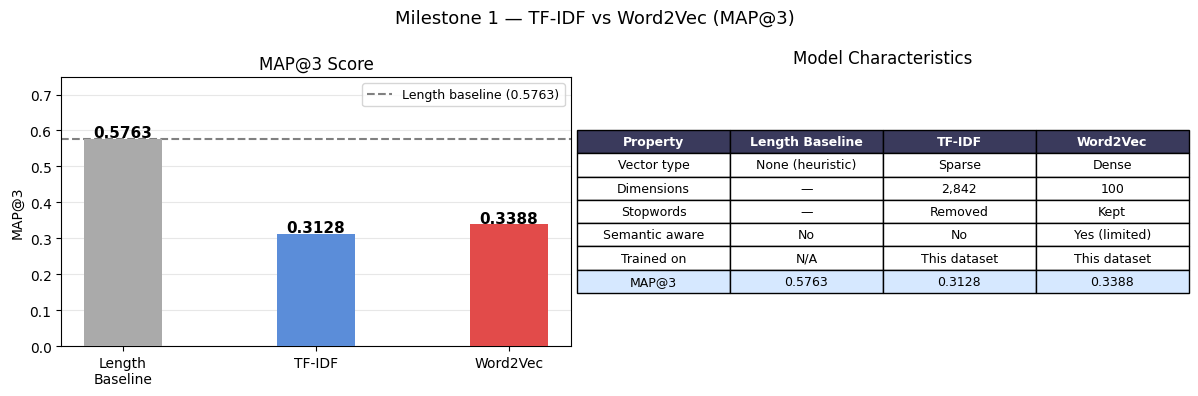


  Milestone 1 Summary
  Length baseline MAP@3 : 0.5763  ← EDA dummy
  TF-IDF          MAP@3 : 0.3128
  Word2Vec        MAP@3 : 0.3388
  Best model            : Length Baseline
 

📊 Key Insight from Milestone 1:
---------------------------------------------
  Both TF-IDF and Word2Vec scored BELOW the dummy case(length-rank heuristic)
  length-rank heuristic (0.57 vs ~0.31-0.34).

  Why? Science MCQ prompts and answers share few
  keywords — e.g. 'What is the metallicity?' vs
  '8 times less than the Sun' — zero word overlap.
  TF-IDF and Word2Vec trained on ~2000 rows cannot
  bridge this semantic gap.

  This motivates Milestone 2: pre-trained sentence-
  transformers (all-MiniLM, sentence-BERT) that
  understand paraphrasing and domain semantics
  should decisively beat even the length baseline.
-----------------------------------------------


In [13]:
models = ['TF-IDF', 'Word2Vec']
scores = [map3_tfidf, map3_w2v]
colors = ['#5B8DD9', '#E24B4A']

# ------ Length-rank baseline (EDA dummy submission) -------------
OPTIONS = ['A', 'B', 'C', 'D', 'E']

def top3_by_length(row):
    lengths = {c: len(row[c]) for c in OPTIONS}
    return ' '.join(sorted(lengths, key=lengths.get, reverse=True)[:3])

train_df['length_pred'] = train_df.apply(top3_by_length, axis=1)
map3_length = mapk(train_df, 'length_pred')

print(f"Length baseline MAP@3 : {map3_length:.4f}")
print(f"TF-IDF          MAP@3 : {map3_tfidf:.4f}")
print(f"Word2Vec        MAP@3 : {map3_w2v:.4f}")

# ----------- Plot -------------------
all_models  = ['Length\nBaseline', 'TF-IDF', 'Word2Vec']
all_scores  = [map3_length, map3_tfidf, map3_w2v]
all_colors  = ['#AAAAAA', '#5B8DD9', '#E24B4A']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle("Milestone 1 — TF-IDF vs Word2Vec (MAP@3)", fontsize=13)

# bar chart
bars = axes[0].bar(all_models, all_scores, color=all_colors, width=0.4, zorder=3)
axes[0].axhline(map3_length, color='gray', lw=1.5, linestyle='--',
                label=f'Length baseline ({map3_length:.4f})')
axes[0].set_ylim(0, max(all_scores) * 1.3)
axes[0].set_ylabel('MAP@3')
axes[0].set_title('MAP@3 Score')
axes[0].legend(fontsize=9)
axes[0].grid(axis='y', alpha=0.3, zorder=0)
for bar, score in zip(bars, all_scores):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                 f'{score:.4f}', ha='center', fontsize=11, fontweight='bold')

# characteristics table
axes[1].axis('off')
table_data = [
    ['Property',       'Length Baseline',    'TF-IDF',           'Word2Vec'],
    ['Vector type',    'None (heuristic)',   'Sparse',            'Dense'],
    ['Dimensions',     '—',                  f'{len(vectorizer.vocabulary_):,}', '100'],
    ['Stopwords',      '—',                  'Removed',           'Kept'],
    ['Semantic aware', 'No',                 'No',                'Yes (limited)'],
    ['Trained on',     'N/A',               'This dataset',      'This dataset'],
    ['MAP@3',          f'{map3_length:.4f}', f'{map3_tfidf:.4f}', f'{map3_w2v:.4f}'],
]
tbl = axes[1].table(cellText=table_data[1:], colLabels=table_data[0],
                    loc='center', cellLoc='center')
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1.2, 1.6)
for j in range(4):
    tbl[0, j].set_facecolor('#3A3A5C')
    tbl[0, j].set_text_props(color='white', fontweight='bold')
for j in range(4):
    tbl[6, j].set_facecolor('#D6E8FF')  # highlight MAP@3 row
axes[1].set_title('Model Characteristics', pad=10)

plt.tight_layout()
plt.savefig('milestone1_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# ------------ Summary ------------------
winner = max(zip(all_scores, all_models), key=lambda x: x[0])[1].replace('\n', ' ')
print(f"\n{'='*47}")
print(f"  Milestone 1 Summary")
print(f"{'='*47}")
print(f"  Length baseline MAP@3 : {map3_length:.4f}  ← EDA dummy")
print(f"  TF-IDF          MAP@3 : {map3_tfidf:.4f}")
print(f"  Word2Vec        MAP@3 : {map3_w2v:.4f}")
print(f"  Best model            : {winner}")
print(f"{'='*47}")
print(" ")

print(
    "\n📊 Key Insight from Milestone 1:"
    "\n---------------------------------------------"
    "\n  Both TF-IDF and Word2Vec scored BELOW the dummy case(length-rank heuristic)"
    "\n  length-rank heuristic (0.57 vs ~0.31-0.34)."
    "\n"
    "\n  Why? Science MCQ prompts and answers share few"
    "\n  keywords — e.g. 'What is the metallicity?' vs"
    "\n  '8 times less than the Sun' — zero word overlap."
    "\n  TF-IDF and Word2Vec trained on ~2000 rows cannot"
    "\n  bridge this semantic gap."
    "\n"
    "\n  This motivates Milestone 2: pre-trained sentence-"
    "\n  transformers (all-MiniLM, sentence-BERT) that"
    "\n  understand paraphrasing and domain semantics"
    "\n  should decisively beat even the length baseline."
    "\n-----------------------------------------------"
)

## Milestone 1 Q/A

In [14]:
OPTIONS = ['A', 'B', 'C', 'D', 'E']
train_df = train_dataset.copy()

# -------- Q1: Frequency distribution of correct answers ---------
freq = train_df['answer'].value_counts()
print("=== Q1: Answer Frequency Distribution ===")
print(freq.to_string())
most_frequent_count  = freq.iloc[0]
least_frequent_count = freq.iloc[-1]
q1_answer = most_frequent_count + least_frequent_count
print(f"\nMost frequent  : {freq.index[0]}  →  {most_frequent_count}")
print(f"Least frequent : {freq.index[-1]}  →  {least_frequent_count}")
print(f"Sum (Q1 answer): {q1_answer}")

# --------- Q2: Unique words in cleaned prompt column ------------------
def clean_text(text):
    text = str(text).lower()
    text = text.translate(str.maketrans('', '', string.punctuation))
    return text

cleaned_prompts = train_df['prompt'].apply(clean_text)
all_words = set()
for prompt in cleaned_prompts:
    all_words.update(prompt.split())

q2_answer = len(all_words)
print(f"\n=== Q2: Vocabulary size (unique words in cleaned prompts) ===")
print(f"Vocabulary size: {q2_answer}")

# -------- Q3: Words left after stop word removal for Row ID 1 -----------
row1_prompt = cleaned_prompts.iloc[0]   # Row ID 1 = index 0
row1_words  = row1_prompt.split()
filtered    = [w for w in row1_words if w not in ENGLISH_STOP_WORDS]
q3_answer   = len(filtered)
print(f"\n=== Q3: Words in Row ID 1 prompt after stop word removal ===")
print(f"Cleaned prompt of row 1 : {row1_prompt}")
print(f"Words before removing stop words : {row1_words}")
print(f"Words after removing stop words : {filtered}")
print(f"Count (Q3 answer): {q3_answer}")

# ── Q4: TF-IDF vocabulary size (prompt + all options combined) ─────────────────
all_texts = []
for col in ['prompt', 'A', 'B', 'C', 'D', 'E']:
    all_texts.extend(train_df[col].tolist())

vectorizer_q4 = TfidfVectorizer(stop_words='english')
vectorizer_q4.fit(all_texts)
q4_answer = len(vectorizer_q4.vocabulary_)
print(f"\n=== Q4: TF-IDF vocabulary size (all prompts + options) ===")
print(f"Feature columns (Q4 answer): {q4_answer}")

# ------- Q5: Cosine similarity between prompt and option A for Row ID 1 ----------
row1 = train_df.iloc[0]
vecs = vectorizer_q4.transform([row1['prompt'], row1['A']])
q5_answer = cosine_similarity(vecs[0], vecs[1])[0][0]
print(f"\n=== Q5: Cosine similarity — Row ID 1, prompt vs option A ===")
print(f"Prompt   : {row1['prompt']}")
print(f"Option A : {row1['A']}")
print(f"Cosine similarity (Q5 answer): {q5_answer:.4f}")

# -------- Q6: % of rows where highest cosine sim option = correct answer ---------
def tfidf_top1(row):
    texts = [row['prompt']] + [row[o] for o in OPTIONS]
    vecs = vectorizer_q4.transform(texts)
    prompt_vec = vecs[0]
    sims = {o: cosine_similarity(prompt_vec, vecs[i+1])[0][0] for i, o in enumerate(OPTIONS)}
    return max(sims, key=sims.get)

train_df['tfidf_top1'] = train_df.apply(tfidf_top1, axis=1)
q6_answer = (train_df['tfidf_top1'] == train_df['answer']).mean() * 100
print(f"\n=== Q6: % rows where top TF-IDF cosine sim = correct answer ===")
print(f"Accuracy (Q6 answer): {q6_answer:.2f}%")

# --------- Q7: MAP@3 if ground truth = C and prediction = C A B -----------------
q7_answer = 1.0 / ((['C', 'A', 'B'].index('C')) + 1)
print(f"\n=== Q7: MAP@3 — ground truth C, prediction C A B ===")
print(f"C is at position 1 → 1/1 = {q7_answer:.4f}")

# ---------- Q8: MAP@3 if ground truth = B and prediction = D B E -----------
q8_answer = 1.0 / ((['D', 'B', 'E'].index('B')) + 1)
print(f"\n=== Q8: MAP@3 — ground truth B, prediction D B E ===")
print(f"B is at position 2 → 1/2 = {q8_answer:.4f}")

# ----------- Q9: Majority class baseline MAP@3 ------------------
top3_answers = freq.index[:3].tolist()   # top 3 most frequent answer letters
static_pred = ' '.join(top3_answers)
train_df['majority_pred'] = static_pred

def apk(actual, predicted, k=3):
    predicted = predicted[:k]
    if actual not in predicted:
        return 0.0
    return 1.0 / (predicted.index(actual) + 1)

def mapk(df, pred_col):
    return df.apply(lambda row: apk(row['answer'], row[pred_col].split()), axis=1).mean()

q9_answer = mapk(train_df, 'majority_pred')
print(f"\n=== Q9: Majority class baseline MAP@3 ===")
print(f"Static prediction for every row: '{static_pred}'")
print(f"MAP@3 (Q9 answer): {q9_answer:.4f}")

# ------ Q10: TF-IDF pipeline MAP@3 across entire train set -----------
# (reuses map3_tfidf already computed above — same pipeline)
print(f"\n=== Q10: TF-IDF pipeline MAP@3 (entire train set) ===")
print(f"MAP@3 (Q10 answer): {map3_tfidf:.4f}")

# -------------- Summary --------------
print("\n" + "="*55)
print("ANSWERS SUMMARY")
print("="*55)
print(f"  Q1  — most + least frequent count sum : {q1_answer}")
print(f"  Q2  — vocabulary size (prompts)       : {q2_answer}")
print(f"  Q3  — words after stopword removal    : {q3_answer}")
print(f"  Q4  — TF-IDF feature columns          : {q4_answer}")
print(f"  Q5  — cosine sim row1 prompt vs A     : {q5_answer:.4f}")
print(f"  Q6  — top-1 accuracy TF-IDF           : {q6_answer:.2f}%")
print(f"  Q7  — MAP@3 (C predicted as C A B)    : {q7_answer:.4f}")
print(f"  Q8  — MAP@3 (B predicted as D B E)    : {q8_answer:.4f}")
print(f"  Q9  — majority class baseline MAP@3   : {q9_answer:.4f}")
print(f"  Q10 — TF-IDF pipeline MAP@3           : {map3_tfidf:.4f}")
print("="*55)

=== Q1: Answer Frequency Distribution ===
answer
B    490
C    459
A    369
D    358
E    324

Most frequent  : B  →  490
Least frequent : E  →  324
Sum (Q1 answer): 814

=== Q2: Vocabulary size (unique words in cleaned prompts) ===
Vocabulary size: 859

=== Q3: Words in Row ID 1 prompt after stop word removal ===
Cleaned prompt of row 1 : pick the best possible answer what is martin heideggers view on the relationship between time and human existence among the listed options
Words before removing stop words : ['pick', 'the', 'best', 'possible', 'answer', 'what', 'is', 'martin', 'heideggers', 'view', 'on', 'the', 'relationship', 'between', 'time', 'and', 'human', 'existence', 'among', 'the', 'listed', 'options']
Words after removing stop words : ['pick', 'best', 'possible', 'answer', 'martin', 'heideggers', 'view', 'relationship', 'time', 'human', 'existence', 'listed', 'options']
Count (Q3 answer): 13

=== Q4: TF-IDF vocabulary size (all prompts + options) ===
Feature columns (Q4 answ

In [15]:
# # ------------------submission using word2vec ----------------------
# # --- Apply same text cleaning + tokenization to test set ------

# test_df = test_dataset.copy()
# print("=========================")
# print(test_df.isna().sum())
# print("====================")
# print(test_df.apply(text_missing).T)

# # 1. Clean (same as train)
# for col in ['prompt', 'A', 'B', 'C', 'D', 'E']:
#     test_df[col] = test_df[col].str.strip().str.replace(r'\s+', ' ', regex=True)

# # 2. Tokenize for Word2Vec (same tokenize_w2v function used on train)
# for col in ['prompt', 'A', 'B', 'C', 'D', 'E']:
#     test_df[f'{col}_w2v'] = test_df[col].apply(lambda x: tokenize(x, remove_stopwords=False))

# # 3. Predict top-3 using trained w2v_model
# test_df['w2v_pred'] = test_df.apply(get_top3_w2v, axis=1)

# print("Sample test predictions:")
# print(test_df[['prompt', 'w2v_pred']].head(5).to_string())

# # 4. Build submission file
# submission_m1 = pd.DataFrame({
#     'id':         test_df['id'],
#     'prediction': test_df['w2v_pred'],
# })

# submission_m1.to_csv('submission_m1.csv', index=False)
# print(f"\n✓ submission_m1.csv saved  ({len(submission_m1)} rows)")
# print(submission_m1.head(10).to_string(index=False))

## Milestone 2 — Enter the Transformers (use of pretrained models)

We use two libraries (huggingFace):
- `transformers` — provides model architectures, tokenizers, and pipelines (HuggingFace)
- `sentence-transformers` — wraps transformer models to produce fixed-size sentence embeddings directly
- 
- Approach 1 — BERT / RoBERTa
- Approach 2 — Sentence Transformers
- Approach 3 — Zero-shot Classification
- Evaluation and Summary
- Generate Submission

In [16]:
print("torch version :", torch.__version__)
print("CUDA available :", torch.cuda.is_available())
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device :", device)

train_df = train_dataset.copy()
test_df = test_dataset.copy()

torch version : 2.10.0+cu128
CUDA available : True
Using device : cuda


### Milestone 2a (loading a pretrained bert model - roberta-base)

In [17]:
BERT_MODEL = "roberta-base"   # pretrained model name

bert_tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL)
bert_model = AutoModel.from_pretrained(BERT_MODEL)      # downloads the pretrained weights
bert_model.eval()   # disables dropouts - freeze the behavior — no dropout, no randomness

if torch.cuda.is_available():
    bert_model = bert_model.to(device)

print(f"Loaded : {BERT_MODEL}")
print(f"Layers : {bert_model.config.num_hidden_layers}")
print(f"Hidden : {bert_model.config.hidden_size}")
print(f"Params : {sum(p.numel() for p in bert_model.parameters()):,}")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loaded : roberta-base
Layers : 12
Hidden : 768
Params : 124,645,632


In [18]:
def get_cls_embeddings(texts, tokenizer, model, batch_size=32):
    all_vecs = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i: i + batch_size]
        encoded = tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors='pt'
        )

        if torch.cuda.is_available():
            encoded = {k: v.to(device) for k, v in encoded.items()}

        with torch.no_grad():
            output = bert_model(**encoded)

        # output.last_hidden_state shape: (batch, seq_len, hidden_size)
        # index 0 along seq_len = [CLS] token
        cls_vecs = output.last_hidden_state[:, 0, :]   # (batch, hidden_size)
        all_vecs.append(cls_vecs.cpu().numpy())  # cls vector from each batch is appended to all vecs

    return np.vstack(all_vecs)   # (N, hidden_size)

sample_vec = get_cls_embeddings(["What is the speed of light?"], bert_tokenizer, bert_model)
print(f"CLS vector shape : {sample_vec.shape}")   # (1, 768)
print(f"First 5 values   : {sample_vec[0][:5]}")

CLS vector shape : (1, 768)
First 5 values   : [-0.03589788  0.11314515 -0.05285056 -0.10897306  0.03441217]


In [19]:
OPTIONS = ['A', 'B', 'C', 'D', 'E']

# Encode train set
print("Encoding train prompts...")
train_bert_prompt = get_cls_embeddings(train_df['prompt'].tolist(), bert_tokenizer, bert_model)

train_bert_options = {}
for opt in OPTIONS:
    print(f"Encoding train option {opt}...")
    train_bert_options[opt] = get_cls_embeddings(train_df[opt].tolist(), bert_tokenizer, bert_model)

# Encode test set
print("\nEncoding test prompts...")
test_bert_prompt = get_cls_embeddings(test_df['prompt'].tolist(), bert_tokenizer, bert_model)

test_bert_options = {}
for opt in OPTIONS:
    print(f"Encoding test option {opt}...")
    test_bert_options[opt] = get_cls_embeddings(test_df[opt].tolist(), bert_tokenizer, bert_model)

print("\nAll BERT embeddings done.")
print(f"train_bert_prompt shape : {train_bert_prompt.shape}")

Encoding train prompts...
Encoding train option A...
Encoding train option B...
Encoding train option C...
Encoding train option D...
Encoding train option E...

Encoding test prompts...
Encoding test option A...
Encoding test option B...
Encoding test option C...
Encoding test option D...
Encoding test option E...

All BERT embeddings done.
train_bert_prompt shape : (2000, 768)


In [20]:
def bert_top3(prompt_vec, option_vecs_dict):
    """Given CLS vectors, rank options by cosine similarity to prompt."""
    scores = {
        opt: cosine_similarity(prompt_vec.reshape(1, -1), option_vecs_dict[opt].reshape(1, -1))[0][0]
        for opt in OPTIONS
    }
    return ' '.join(sorted(scores, key=scores.get, reverse=True)[:3])

# Train predictions (for MAP@3)
train_df['bert_pred'] = [
    bert_top3(
        train_bert_prompt[i],
        {opt: train_bert_options[opt][i] for opt in OPTIONS}
    )
    for i in range(len(train_df))
]

# Test predictions (for submission)
test_df['bert_pred'] = [
    bert_top3(
        test_bert_prompt[i],
        {opt: test_bert_options[opt][i] for opt in OPTIONS}
    )
    for i in range(len(test_df))
]

map3_bert = mapk(train_df, 'bert_pred')
print(f"RoBERTa (CLS pooling) MAP@3 : {map3_bert:.4f}")    # 0.3336
print("\nSample predictions (answer | bert_pred):")
print(train_df[['answer', 'bert_pred']].head(5).to_string())

RoBERTa (CLS pooling) MAP@3 : 0.3336

Sample predictions (answer | bert_pred):
  answer bert_pred
0      B     D C A
1      A     B C E
2      C     A B C
3      B     D C E
4      A     E D C


### Milestone 2b (sentence transformers approach)

In [21]:
sbert_model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2', device=device)
print("Model loaded:", sbert_model)
print("Embedding dimension:", sbert_model.get_sentence_embedding_dimension())

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Model loaded: SentenceTransformer(
  (0): Transformer({'transformer_task': 'feature-extraction', 'modality_config': {'text': {'method': 'forward', 'method_output_name': 'last_hidden_state'}}, 'module_output_name': 'token_embeddings', 'architecture': 'BertModel'})
  (1): Pooling({'embedding_dimension': 384, 'pooling_mode': 'mean', 'include_prompt': True})
  (2): Normalize({})
)
Embedding dimension: 384


In [22]:
# ---------- ENCODE ALL EMBEDDINGS -----------
OPTIONS = ['A', 'B', 'C', 'D', 'E']

print("Encoding TRAIN prompts...")
train_prompt_emb_sbert = sbert_model.encode(train_df['prompt'].tolist(), batch_size=64,
                                       show_progress_bar=True, convert_to_numpy=True)
print("Encoding TEST prompts...")
test_prompt_emb_sbert = sbert_model.encode(test_df['prompt'].tolist(), batch_size=64,
                                        show_progress_bar=True, convert_to_numpy=True)

train_option_emb = {}
test_option_emb = {}
for opt in OPTIONS:
    print(f"Encoding option {opt}...")
    train_option_emb[opt] = sbert_model.encode(train_df[opt].tolist(), batch_size=64,
                                                show_progress_bar=False, convert_to_numpy=True)
    test_option_emb[opt] = sbert_model.encode(test_df[opt].tolist(), batch_size=64,
                                                  show_progress_bar=False, convert_to_numpy=True)

print("\nAll embeddings computed.")
print(f"Train prompt shape : {train_prompt_emb_sbert.shape}")
print(f"Test  prompt shape : {test_prompt_emb_sbert.shape}")
print(f"Option A shape     : {test_option_emb['A'].shape}")

Encoding TRAIN prompts...


Batches:   0%|          | 0/32 [00:00<?, ?it/s]

Encoding TEST prompts...


Batches:   0%|          | 0/8 [00:00<?, ?it/s]

Encoding option A...
Encoding option B...
Encoding option C...
Encoding option D...
Encoding option E...

All embeddings computed.
Train prompt shape : (2000, 384)
Test  prompt shape : (500, 384)
Option A shape     : (500, 384)


In [23]:
def sbert_top3(prompt_vec, option_vecs):
    scores = {
        opt: cosine_similarity(prompt_vec.reshape(1, -1), option_vecs[opt].reshape(1, -1))[0][0]
        for opt in OPTIONS
    }
    return ' '.join(sorted(scores, key=scores.get, reverse=True)[:3])

test_df['sbert_pred'] = [
    sbert_top3(test_prompt_emb_sbert[i], {opt: test_option_emb[opt][i] for opt in OPTIONS})
    for i in range(len(test_df))
]

train_df['sbert_pred'] = [
    sbert_top3(train_prompt_emb_sbert[i], {opt: train_option_emb[opt][i] for opt in OPTIONS})
    for i in range(len(train_df))
]

map3_sbert = mapk(train_df, 'sbert_pred')
print(f"sbert MAP@3 : {map3_sbert:.4f}")
print("\nSample SBERT predictions (answer | sbert_pred):")
print(train_df[['answer', 'sbert_pred']].head(5).to_string())

sbert MAP@3 : 0.4231

Sample SBERT predictions (answer | sbert_pred):
  answer sbert_pred
0      B      C D B
1      A      B C D
2      C      B A D
3      B      C D B
4      A      E D A


### Milestone 2c (zero shot classification - pretrained NLI models)

In [24]:
# zero shot classification

""" Concept: Natural Language Inference (NLI) models are trained to predict 
             whether a *hypothesis* is entailed by, contradicts, or is neutral to a *premise*.

We repurpose this:
- **Premise** = the MCQ prompt (the question)
- **Hypothesis** = each answer option

The model gives a probability that the option is "entailed" by the question — 
which approximates "how well does this option answer the question?".

This is **zero-shot** because we never fine-tune on MCQ data — 
we're using the model's pre-trained understanding of language entailment """

zs_pipeline = pipeline(
    "zero-shot-classification",
    model="facebook/bart-large-mnli",
    device=0 if torch.cuda.is_available() else -1
)
print("Zero-shot pipeline loaded.")

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

Zero-shot pipeline loaded.


In [25]:
def zeroshot_top3(prompt, options_dict):
    """
    options_dict: {'A': text, 'B': text, ...}
    Returns a string like 'B A D' (top 3 by entailment score)
    """
    candidate_labels = list(options_dict.values())
    result = zs_pipeline(prompt, candidate_labels, multi_label=False)

    label_to_opt = {v: k for k, v in options_dict.items()}
    ranked_opts = [label_to_opt[label] for label in result['labels'][:3]]
    return ' '.join(ranked_opts)


print("Running zero-shot classification on train set")
train_df['zs_pred'] = [
    zeroshot_top3(
        row['prompt'],
        {opt: row[opt] for opt in OPTIONS}
    )
    for _, row in tqdm(train_df.iterrows(), total=len(train_df))
]

print("\nRunning on test set...")
test_df['zs_pred'] = [
    zeroshot_top3(
        row['prompt'],
        {opt: row[opt] for opt in OPTIONS}
    )
    for _, row in tqdm(test_df.iterrows(), total=len(test_df))
]

map3_zeroshot = mapk(train_df, 'zs_pred')
print(f"Zero shot MAP3 score: {map3_zeroshot:.4f}")
print("\nSample zero-shot predictions (answer | zs_pred):")
print(train_df[['answer', 'zs_pred']].head(5).to_string())

Running zero-shot classification on train set


100%|██████████| 2000/2000 [04:35<00:00,  7.26it/s]



Running on test set...


100%|██████████| 500/500 [01:06<00:00,  7.48it/s]

Zero shot MAP3 score: 0.5658

Sample zero-shot predictions (answer | zs_pred):
  answer zs_pred
0      B   B A D
1      A   E D A
2      C   B C E
3      B   B A D
4      A   A B E


In [26]:
def apk(actual, predicted, k=3):
    predicted = predicted[:k]
    if actual not in predicted:
        return 0.0
    return 1.0 / (predicted.index(actual) + 1)

def mapk(df, pred_col):
    return df.apply(lambda row: apk(row['answer'], row[pred_col].split()), axis=1).mean()

# Recompute Milestone 1 baselines (in case cell order changed)
def top3_by_length(row):
    lengths = {c: len(row[c]) for c in OPTIONS}
    return ' '.join(sorted(lengths, key=lengths.get, reverse=True)[:3])
train_df['length_pred'] = train_df.apply(top3_by_length, axis=1)

# map3_length = mapk(train_df, 'length_pred')
map3_bert   = mapk(train_df, 'bert_pred')
map3_sbert  = mapk(train_df, 'sbert_pred')
map3_zs     = mapk(train_df, 'zs_pred')

# print(f"Length baseline MAP@3 : {map3_length:.4f}")
print(f"TF-IDF          MAP@3 : {map3_tfidf:.4f}")
print(f"Word2Vec        MAP@3 : {map3_w2v:.4f}")
print(f"RoBERTa (CLS)   MAP@3 : {map3_bert:.4f}")
print(f"SBERT (MiniLM)  MAP@3 : {map3_sbert:.4f}")
print(f"Zero-shot BART  MAP@3 : {map3_zs:.4f}")

TF-IDF          MAP@3 : 0.3128
Word2Vec        MAP@3 : 0.3388
RoBERTa (CLS)   MAP@3 : 0.3336
SBERT (MiniLM)  MAP@3 : 0.4231
Zero-shot BART  MAP@3 : 0.5658


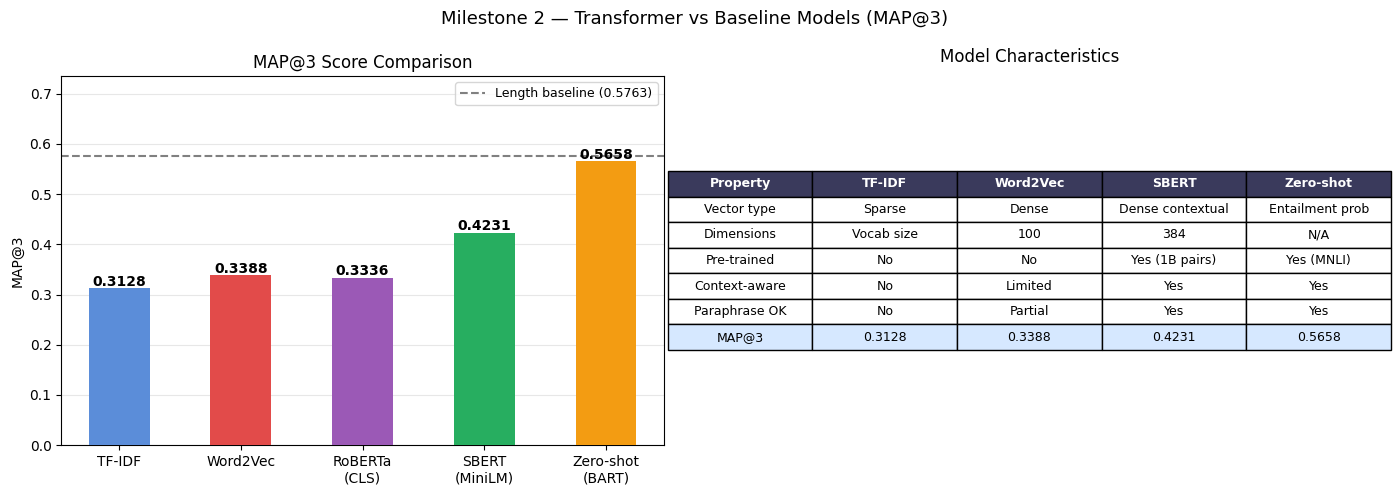

In [27]:
# ---- Visualisation ----
all_models = ['TF-IDF', 'Word2Vec', 'RoBERTa\n(CLS)', 'SBERT\n(MiniLM)', 'Zero-shot\n(BART)']
all_scores = [map3_tfidf, map3_w2v, map3_bert, map3_sbert, map3_zs]
all_colors = ['#5B8DD9', '#E24B4A', '#9B59B6', '#27AE60', '#F39C12']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Milestone 2 — Transformer vs Baseline Models (MAP@3)", fontsize=13)

# Bar chart
bars = axes[0].bar(all_models, all_scores, color=all_colors, width=0.5, zorder=3)
axes[0].axhline(map3_length, color='gray', lw=1.5, linestyle='--',
                label=f'Length baseline ({map3_length:.4f})')
axes[0].set_ylim(0, max(all_scores) * 1.3)
axes[0].set_ylabel('MAP@3')
axes[0].set_title('MAP@3 Score Comparison')
axes[0].legend(fontsize=9)
axes[0].grid(axis='y', alpha=0.3, zorder=0)
for bar, score in zip(bars, all_scores):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                 f'{score:.4f}', ha='center', fontsize=10, fontweight='bold')

# Characteristics table
axes[1].axis('off')
table_data = [
    ['Property',       'TF-IDF',       'Word2Vec',    'SBERT',                  'Zero-shot'],
    ['Vector type',    'Sparse',       'Dense',       'Dense contextual',        'Entailment prob'],
    ['Dimensions',     'Vocab size',   '100',         '384',                     'N/A'],
    ['Pre-trained',    'No',           'No',          'Yes (1B pairs)',           'Yes (MNLI)'],
    ['Context-aware',  'No',           'Limited',     'Yes',                     'Yes'],
    ['Paraphrase OK',  'No',           'Partial',     'Yes',                     'Yes'],
    ['MAP@3',          f'{map3_tfidf:.4f}', f'{map3_w2v:.4f}', f'{map3_sbert:.4f}', f'{map3_zs:.4f}'],
]
tbl = axes[1].table(cellText=table_data[1:], colLabels=table_data[0],
                    loc='center', cellLoc='center')
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1.2, 1.6)
for j in range(5):
    tbl[0, j].set_facecolor('#3A3A5C')
    tbl[0, j].set_text_props(color='white', fontweight='bold')
for j in range(5):
    tbl[6, j].set_facecolor('#D6E8FF')
axes[1].set_title('Model Characteristics', pad=10)

plt.tight_layout()
plt.savefig('milestone2_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## Milestone 2 (Q/A)

In [28]:
# -------- Q1: Load train.csv with HF datasets (NOT pandas), build combined_text --------
hf_train = load_dataset(
    "csv",
    data_files="/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv"
)["train"]    # extract the train dataset using the train key from the dictionary returned from load_dataset

def add_combined_text(example):
    example["combined_text"] = example["prompt"] + " " + example["A"]
    return example

hf_train = hf_train.map(add_combined_text)   # map calls the add_combined_text function for every row of hf_train
 
q1_answer = len(hf_train[51]["combined_text"])
print("=== Q1: len(combined_text) for row index 51 ===")
print(f"combined_text[51]: {hf_train[51]['combined_text']}")
print(f"Character length (Q1 answer): {q1_answer}")


# -------- Q2: bert-base-uncased tokenizer vocab size --------
bert_uncased_tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
q2_answer = bert_uncased_tokenizer.vocab_size
print(f"\n=== Q2: bert-base-uncased vocab size ===")
print(f"Vocab size (Q2 answer): {q2_answer}")


print(' ')
# -------- Q3: [SEP] token ID --------
q3_answer = bert_uncased_tokenizer.sep_token_id
print("=== Q3: [SEP] token ID ===")
print(f"[SEP] token ID (Q3 answer): {q3_answer}")

# -------- Q4: Shape of input_ids after batch-tokenizing entire prompt column --------
all_prompts_q4 = [str(p) for p in hf_train["prompt"]]
encoded_q4 = bert_uncased_tokenizer(
    all_prompts_q4,
    padding="max_length",
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

q4_answer = tuple(encoded_q4["input_ids"].shape)
print(f"\n=== Q4: Shape of input_ids tensor ===")
print(f"input_ids shape (Q4 answer): {q4_answer}")
print(' ')

# ------ BERT / ROBERTA Architecture and Attention Mechanisms ----------
# -------- Q5: Size of each attention head (hidden_size / num_heads) --------
hidden_size_q5 = 768
num_heads_q5 = 12
q5_answer = hidden_size_q5 // num_heads_q5
print("=== Q5: Attention head dimensionality ===")
print(f"{hidden_size_q5} / {num_heads_q5} = {q5_answer} (Q5 answer)")

# -------- Q6: last_hidden_state shape for row ID 0 prompt (default tokenizer settings) --------
bert_uncased_model = AutoModel.from_pretrained("bert-base-uncased")
bert_uncased_model.eval()

row0_prompt = hf_train[0]["prompt"]
enc_row0 = bert_uncased_tokenizer(row0_prompt, return_tensors="pt")   # (1, 31) 'single prompt row 0'

with torch.no_grad():
    out_row0 = bert_uncased_model(**enc_row0)

q6_answer = tuple(out_row0.last_hidden_state.shape)
print(f"\n=== Q6: last_hidden_state shape (row ID 0 prompt) ===")
print(f"Token count : {enc_row0['input_ids'].shape}")
print(f"Shape (Q6 answer): {q6_answer}")
print(' ')

# -------- Q7: Sum of first 5 float values of the [CLS] embedding --------
cls_vec_row0 = out_row0.last_hidden_state[0, 0, :]   # [CLS] is token index 0
q7_answer = round(cls_vec_row0[:5].sum().item(), 4)
print("=== Q7: Sum of first 5 [CLS] vector values ===")
print(f"First 5 values : {cls_vec_row0[:5].tolist()}")
print(f"Sum (Q7 answer): {q7_answer}")

# -------- Q8: Attention weight from [CLS] to "fusion", last layer, head 0 --------
bert_attn_model = AutoModel.from_pretrained("bert-base-uncased", output_attentions=True)
bert_attn_model.eval()

sentence_q8 = "Light-ion fusion is a technique."
enc_q8 = bert_uncased_tokenizer(sentence_q8, return_tensors="pt")

with torch.no_grad():
    out_q8 = bert_attn_model(**enc_q8)

tokens_q8 = bert_uncased_tokenizer.convert_ids_to_tokens(enc_q8["input_ids"][0])
fusion_idx = tokens_q8.index("fusion")   # get the index of the fusion word

last_layer_attn = out_q8.attentions[-1]        # (batch, num_heads, seq, seq)
head0_attn = last_layer_attn[0, 0]             # (seq, seq) — first head

q8_answer = round(head0_attn[0, fusion_idx].item(), 4)
print(f"\n=== Q8: [CLS] -> 'fusion' attention weight (last layer, head 0) ===")
print(f"Tokens          : {tokens_q8}")
print(f"'fusion' index  : {fusion_idx}")
print(f"Attention weight (Q8 answer): {q8_answer}")

# -------- Q9: Cosine similarity (prompt vs Option B, row ID 0) using MiniLM --------
minilm_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)

row0_q9 = hf_train[0]
prompt_emb_q9 = minilm_model.encode(row0_q9["prompt"], convert_to_tensor=True)
optionB_emb_q9 = minilm_model.encode(row0_q9["B"], convert_to_tensor=True)

q9_answer = round(util.cos_sim(prompt_emb_q9, optionB_emb_q9).item(), 4)
print("=== Q9: MiniLM cosine similarity — prompt vs Option B (row ID 0) ===")
print(f"Prompt   : {row0_q9['prompt']}")
print(f"Option B : {row0_q9['B']}")
print(f"Cosine similarity (Q9 answer): {q9_answer}")

=== Q1: len(combined_text) for row index 51 ===
combined_text[51]: Determine the correct option: What is the reason behind the designation of Class L dwarfs, and what is their color and composition? among the listed options. Class L dwarfs are hotter than M stars and are designated L because L is the remaining letter alphabetically closest to M. They are bright blue in color and are brightest in ultraviolet. Their atmosphere is hot enough to allow metal hydrides and alkali metals to be prominent in their spectra. Some of these objects have masses large enough to support hydrogen fusion and are therefore stars, but most are of substellar mass and are therefore brown dwarfs.
Character length (Q1 answer): 614

=== Q2: bert-base-uncased vocab size ===
Vocab size (Q2 answer): 30522
 
=== Q3: [SEP] token ID ===
[SEP] token ID (Q3 answer): 102

=== Q4: Shape of input_ids tensor ===
input_ids shape (Q4 answer): (2000, 128)
 
=== Q5: Attention head dimensionality ===
768 / 12 = 64 (Q5 answer)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


=== Q6: last_hidden_state shape (row ID 0 prompt) ===
Token count : torch.Size([1, 31])
Shape (Q6 answer): (1, 31, 768)
 
=== Q7: Sum of first 5 [CLS] vector values ===
First 5 values : [-0.46766412258148193, -0.07544441521167755, -0.20190182328224182, -0.007064236328005791, -0.4480222463607788]
Sum (Q7 answer): -1.2001


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


=== Q8: [CLS] -> 'fusion' attention weight (last layer, head 0) ===
Tokens          : ['[CLS]', 'light', '-', 'ion', 'fusion', 'is', 'a', 'technique', '.', '[SEP]']
'fusion' index  : 4
Attention weight (Q8 answer): 0.1025


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

=== Q9: MiniLM cosine similarity — prompt vs Option B (row ID 0) ===
Prompt   : Pick the best possible answer: What is Martin Heidegger's view on the relationship between time and human existence? among the listed options.
Option B : Martin Heidegger believes that humans do not exist inside time, but that they are time. The relationship to the past is a present awareness of having been, and the relationship to the future involves anticipating a potential possibility, task, or engagement.
Cosine similarity (Q9 answer): 0.7658


In [29]:
OPTIONS = ['A', 'B', 'C', 'D', 'E']
train_q10 = train_dataset.copy()

# ---- Pipeline 1: TF-IDF cosine similarity (Milestone 1 approach) ----
all_texts_q10 = []
for col in ['prompt'] + OPTIONS:
    all_texts_q10.extend(train_q10[col].tolist())

tfidf_vec_q10 = TfidfVectorizer(stop_words='english')
tfidf_vec_q10.fit(all_texts_q10)

def tfidf_top3(row):
    texts = [row['prompt']] + [row[o] for o in OPTIONS]
    vecs = tfidf_vec_q10.transform(texts)    # fit on all the text and then transform row-wise
    prompt_vec = vecs[0]
    sims = {o: cosine_similarity(prompt_vec, vecs[i + 1])[0][0] for i, o in enumerate(OPTIONS)}
    return sorted(sims, key=sims.get, reverse=True)[:3]

train_q10['tfidf_top3_pred'] = train_q10.apply(tfidf_top3, axis=1)

# ---- Pipeline 2: all-MiniLM-L6-v2 embeddings for prompt + all 5 options ----
minilm_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)

print("Encoding prompts with MiniLM...")
prompt_emb_all = minilm_model.encode(
    train_q10['prompt'].tolist(), batch_size=64, show_progress_bar=True, convert_to_numpy=True
)

option_emb_all = {}
for opt in OPTIONS:
    print(f"Encoding option {opt}...")
    option_emb_all[opt] = minilm_model.encode(
        train_q10[opt].tolist(), batch_size=64, show_progress_bar=False, convert_to_numpy=True
    )

def minilm_top3(i):
    p_vec = prompt_emb_all[i]
    sims = {
        opt: cosine_similarity(p_vec.reshape(1, -1), option_emb_all[opt][i].reshape(1, -1))[0][0]
        for opt in OPTIONS
    }
    return sorted(sims, key=sims.get, reverse=True)[:3]

train_q10['minilm_top3_pred'] = [minilm_top3(i) for i in range(len(train_q10))]

def apk3(actual, predicted):
    if actual not in predicted:
        return 0.0
    return 1.0 / (predicted.index(actual) + 1)

# -------- Q10: MAP@3 of the MiniLM pipeline across the entire training set --------
q10_answer = train_q10.apply(lambda row: apk3(row['answer'], row['minilm_top3_pred']), axis=1).mean()
print(f"\n=== Q10: MiniLM pipeline MAP@3 (entire train set) ===")
print(f"MAP@3 (Q10 answer): {q10_answer:.4f}")

# -------- Q11: count where correct answer NOT in TF-IDF top3 BUT IS in MiniLM top3 --------
q11_answer = sum(
    (row['answer'] not in row['tfidf_top3_pred']) and (row['answer'] in row['minilm_top3_pred'])
    for _, row in train_q10.iterrows()
)
print(f"\n=== Q11: TF-IDF misses, MiniLM catches (count) ===")
print(f"Count (Q11 answer): {q11_answer}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Encoding prompts with MiniLM...


Batches:   0%|          | 0/32 [00:00<?, ?it/s]

Encoding option A...
Encoding option B...
Encoding option C...
Encoding option D...
Encoding option E...

=== Q10: MiniLM pipeline MAP@3 (entire train set) ===
MAP@3 (Q10 answer): 0.4231

=== Q11: TF-IDF misses, MiniLM catches (count) ===
Count (Q11 answer): 462


In [30]:
zs_pipe_q12 = hf_pipeline(
    "zero-shot-classification",
    model="facebook/bart-large-mnli",
    device=0 if torch.cuda.is_available() else -1
)

row1_q12 = hf_train[1]   # 2nd row = index 1
candidate_labels_q12 = [row1_q12['A'], row1_q12['B'], row1_q12['C']]

# -------- Q12: top-ranked option probability (default softmax) --------
result_q12 = zs_pipe_q12(row1_q12['prompt'], candidate_labels_q12)
q12_answer = round(result_q12['scores'][0], 4)   # candidate with max score is at 0th index
print("=== Q12: Zero-shot top-ranked probability (softmax) ===")
print(f"Prompt  : {row1_q12['prompt']}")
print(f"Labels  : {result_q12['labels']}")
print(f"Scores  : {[round(s, 4) for s in result_q12['scores']]}")
print(f"Top score (Q12 answer): {q12_answer}")

# -------- Q13: absolute difference in summed probabilities, softmax vs independent sigmoids --------
result_q13 = zs_pipe_q12(row1_q12['prompt'], candidate_labels_q12, multi_label=True)
sum_softmax = sum(result_q12['scores'])
sum_sigmoid = sum(result_q13['scores'])
q13_answer = round(abs(sum_softmax - sum_sigmoid), 4)
print(f"\n=== Q13: |sum(softmax) - sum(sigmoid)| ===")
print(f"Sum (softmax, multi_label=False) : {sum_softmax:.4f}")
print(f"Sum (sigmoid, multi_label=True)  : {sum_sigmoid:.4f}")
print(f"Absolute difference (Q13 answer) : {q13_answer}")

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

=== Q12: Zero-shot top-ranked probability (softmax) ===
Prompt  : What is accelerator-based light-ion fusion?
Labels  : ['Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce light-ion fusion reactions. This method is relatively easy to implement and can be done in an efficient manner, requiring only a vacuum tube, a pair of electrodes, and a high-voltage transformer. Fusion can be observed with as little as 10 kV between the electrodes.', 'Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce light-ion fusion reactions. This method is relatively difficult to implement and requires a complex system of vacuum tubes, electrodes, and transformers. Fusion can be observed with as little as 100 kV between the electrodes.', 'Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve partic

In [31]:
flan_tokenizer = AutoTokenizer.from_pretrained("google/flan-t5-small")
flan_model = AutoModelForSeq2SeqLM.from_pretrained("google/flan-t5-small")
flan_model.eval()
if torch.cuda.is_available():
    flan_model = flan_model.to(device)

row0_q14 = hf_train[0]
prompt_q14 = (
    f"Question: {row0_q14['prompt']}. "
    f"Is the correct answer A: {row0_q14['A']} or B: {row0_q14['B']}? "
    f"Answer with just the letter A or B."
)

inputs_q14 = flan_tokenizer(prompt_q14, return_tensors="pt")
if torch.cuda.is_available():
    inputs_q14 = {k: v.to(device) for k, v in inputs_q14.items()}

with torch.no_grad():
    output_ids_q14 = flan_model.generate(**inputs_q14, max_new_tokens=5)

q14_answer = flan_tokenizer.decode(output_ids_q14[0], skip_special_tokens=True)

print("=== Q14: flan-t5-small generated output ===")
print(f"Input prompt : {prompt_q14}")
print(f"Output (Q14 answer): \"{q14_answer}\"")

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

=== Q14: flan-t5-small generated output ===
Input prompt : Question: Pick the best possible answer: What is Martin Heidegger's view on the relationship between time and human existence? among the listed options.. Is the correct answer A: Martin Heidegger believes that humans exist within a time continuum that is infinite and does not have a defined beginning or end. The relationship to the past involves acknowledging it as a historical era, and the relationship to the future involves creating a world that will endure beyond one's own time. or B: Martin Heidegger believes that humans do not exist inside time, but that they are time. The relationship to the past is a present awareness of having been, and the relationship to the future involves anticipating a potential possibility, task, or engagement.? Answer with just the letter A or B.
Output (Q14 answer): "B"


In [32]:
print("MILESTONE 2 Q/A — ANSWERS SUMMARY")
print("=" * 55)
print(f"  Q1  — len(combined_text) row 51 : {q1_answer}")
print(f"  Q2  — bert-base-uncased vocab size : {q2_answer}")
print(f"  Q3  — [SEP] token ID : {q3_answer}")
print(f"  Q4  — input_ids shape (batch tokenize) : {q4_answer}")
print(f"  Q5  — attention head dimensionality : {q5_answer}")
print(f"  Q6  — last_hidden_state shape (row 0) : {q6_answer}")
print(f"  Q7  — sum first 5 [CLS] values : {q7_answer}")
print(f"  Q8  — attention weight [CLS] -> fusion : {q8_answer}")
print(f"  Q9  — MiniLM cosine sim (prompt vs B, row 0) : {q9_answer}")
print(f"  Q10 — MiniLM pipeline MAP@3 : {q10_answer:.4f}")
print(f"  Q11 — TF-IDF miss / MiniLM catch count : {q11_answer}")
print(f"  Q12 — Zero-shot top prob (softmax) : {q12_answer}")
print(f"  Q13 — |sum(softmax) - sum(sigmoid)| : {q13_answer}")
print(f"  Q14 — flan-t5-small generated output : \"{q14_answer}\"")

MILESTONE 2 Q/A — ANSWERS SUMMARY
  Q1  — len(combined_text) row 51 : 614
  Q2  — bert-base-uncased vocab size : 30522
  Q3  — [SEP] token ID : 102
  Q4  — input_ids shape (batch tokenize) : (2000, 128)
  Q5  — attention head dimensionality : 64
  Q6  — last_hidden_state shape (row 0) : (1, 31, 768)
  Q7  — sum first 5 [CLS] values : -1.2001
  Q8  — attention weight [CLS] -> fusion : 0.1025
  Q9  — MiniLM cosine sim (prompt vs B, row 0) : 0.7658
  Q10 — MiniLM pipeline MAP@3 : 0.4231
  Q11 — TF-IDF miss / MiniLM catch count : 462
  Q12 — Zero-shot top prob (softmax) : 0.4575
  Q13 — |sum(softmax) - sum(sigmoid)| : 0.9995
  Q14 — flan-t5-small generated output : "B"


In [33]:
# best_model = max(
#     [('bert_pred', map3_bert), ('sbert_pred', map3_sbert), ('zs_pred', map3_zs)],
#     key=lambda x: x[1]
# )
# print(f"Best model: {best_model[0]}  (MAP@3 = {best_model[1]:.4f})")

# submission = pd.DataFrame({
#     'ID':         test_df['id'],
#     'Prediction': test_df[best_model[0]],
# })
# submission.to_csv('submission_m2.csv', index=False)
# print(submission.head(10).to_string(index=False))
# print(f"\n✓ submission_m2.csv saved  ({len(submission)} rows)")

## Milestone 3 — Context Augmentation with RAG Pipelines

### What is RAG - Retrieval Augmented Generation ?
```
Test question
     │
     ▼
Embed question ──► FAISS(facebook AI similar search) search over Wikipedia passages
                              │
                              ▼
               Top-k real Wikipedia passages retrieved
               e.g. "Mitochondria are organelles that
                     generate ATP through oxidative
                     phosphorylation..."
                              │
                              ▼
  Prompt = "Context: <wiki passages>
            Question: <prompt>
            Options: A/B/C/D/E
            Answer with one letter."
                              │
                              ▼
             Flan-T5 reads context → picks best option
```

### Key difference from M2
| M2 (zero-shot BART) | M3 (RAG + Flan-T5) |
|---|---|
| No external knowledge | Retrieves real Wikipedia articles |
| NLI model, classifies only | Seq2Seq LLM, reads + reasons |
| Answers from weights only | Answers grounded in retrieved facts |

### Datasets to add to this notebook (no internet needed)
- `jjinho/wikipedia-2023-07-faiss-index` — pre-built FAISS index (6.4M Wikipedia article embeddings, already embedded with **all-MiniLM-L6-v2** — same model as M2 SBERT)
- `jjinho/wikipedia-20230701` — plaintext parquet with the actual article text (columns: `id`, `title`, `text`)

Once added, files appear at:
- `/kaggle/input/wikipedia-2023-07-faiss-index/wikipedia_202307.index`
- `/kaggle/input/wikipedia-20230701/wiki_2023_index.parquet`

In [34]:
!pip install faiss-cpu --quiet
import faiss
from transformers import T5ForConditionalGeneration, T5Tokenizer

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
OPTIONS = ['A', 'B', 'C', 'D', 'E']
print(f"Device : {DEVICE}")

train_df = train_dataset.copy()
test_df = test_dataset.copy()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.5/18.5 MB 77.6 MB/s eta 0:00:00
Device : cuda


### Load Pre-built Wikipedia FAISS Index

The dataset `jjinho/wikipedia-2023-07-faiss-index` contains a FAISS index of
**6.4 million Wikipedia article embeddings**, pre-computed with `all-MiniLM-L6-v2`
— the exact same model used in M2 SBERT. So we don't need to embed anything;
just load and search.

### Load Wikipedia Plaintext Passages

The FAISS index stores vector IDs that map 1-to-1 with rows in the parquet file.
When FAISS returns index `i`, we look up row `i` in the parquet to get the actual text.

The parquet has columns: `id`, `title`, `text`
- `text` = title + first sentences of the Wikipedia article (what was embedded)

In [35]:
FAISS_INDEX_PATH = "/kaggle/input/datasets/jjinho/wikipedia-2023-07-faiss-index/wikipedia_202307.index"
WIKI_INDEX_PATH  = "/kaggle/input/datasets/jjinho/wikipedia-20230701/wiki_2023_index.parquet"

print("Loading FAISS index...")
wiki_index = faiss.read_index(FAISS_INDEX_PATH)
print(f"Total vectors: {wiki_index.ntotal:,}  |  dim: {wiki_index.d}")

print("\nLoading wiki_2023_index.parquet...")
wiki_index_df = pd.read_parquet(WIKI_INDEX_PATH)   # no columns= filter — let it load as-is first
print("Rows:", len(wiki_index_df))
print("Columns:", wiki_index_df.columns.tolist())
print(wiki_index_df.head())
print(f"\nparquet rows == faiss.ntotal ? {len(wiki_index_df) == wiki_index.ntotal}")

Loading FAISS index...
Total vectors: 6,286,775  |  dim: 384

Loading wiki_2023_index.parquet...
Rows: 6286775
Columns: ['id', 'title', 'text', 'categories', 'context', 'file']
         id                            title  \
0  49495844  A & B High Performance Firearms   
1   3579086                      A & C Black   
2  62397582            A & F Harvey Brothers   
3  15547032                      A & G Price   
4   8021609               A & M Karagheusian   

                                                text  \
0  A & B High Performance Firearms: A & B High Pe...   
1  A & C Black: A & C Black is a British book pub...   
2  A & F Harvey Brothers: A & F Harvey Brothers, ...   
3  A & G Price: A & G Price Limited is an enginee...   
4  A & M Karagheusian: thumb|right|238px|A portio...   

                                          categories  \
0  [Defunct firearms manufacturers, Defunct manuf...   
1  [Encyclopædia Britannica, Ornithological publi...   
2                            

### Load Retriever (MiniLM)

In [36]:
# ============================================================
# Load MiniLM retriever (same as Milestone 2 SBERT)
# ============================================================
print("Loading MiniLM retriever...")
retriever = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')
print("Retriever ready.")
print(" ")

# ============================================================
# Retrieve top-k real Wikipedia passages for a query
# ============================================================

def retrieve_wiki(query: str, k: int = 3) -> list[str]:
    """
    Embed query, search Wikipedia FAISS index, return top-k article texts.
    """
    query_vec = retriever.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True,
    ).astype('float32')

    _, indices = wiki_index.search(query_vec, k)

    passages = []
    for idx in indices[0]:
        if 0 <= idx < len(wiki_index_df):
            row = wiki_index_df.iloc[idx]
            passages.append(f"{row['title']}: {row['text'][:300]}")
    return passages


# ── Sanity check ──
sample_q = test_df.iloc[0]['prompt']
print(f"Query: {sample_q}") 
print()
print("Retrieved Wikipedia context:")
for i, p in enumerate(retrieve_wiki(sample_q, k=3), 1):
    print(f"  [{i}] {p[:150]}")
    print()

Loading MiniLM retriever...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Retriever ready.
 
Query: Pick the best possible answer: What is the relationship between the Hamiltonians and eigenstates in supersymmetric quantum mechanics? carefully.

Retrieved Wikipedia context:
  [1] Supersymmetric quantum mechanics: Supersymmetric quantum mechanics: In theoretical physics, supersymmetric quantum mechanics is an area of research wh

  [2] Hamiltonian (quantum mechanics): Hamiltonian (quantum mechanics): In quantum mechanics, the Hamiltonian of a system is an operator corresponding to th

  [3] Molecular Hamiltonian: Molecular Hamiltonian: In atomic, molecular, and optical physics and quantum chemistry, the molecular Hamiltonian is the Hamilt



### Load Flan-T5 as Reader LLM

In [37]:
# ============================================================
# Load Flan-T5-base reader
# ============================================================

FLAN_MODEL = "google/flan-t5-base"

print(f"Loading {FLAN_MODEL}...")
flan_tokenizer = T5Tokenizer.from_pretrained(FLAN_MODEL)
flan_model = T5ForConditionalGeneration.from_pretrained(FLAN_MODEL).to(DEVICE)
flan_model.eval()
print("Flan-T5 ready.")

Loading google/flan-t5-base...


Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

Flan-T5 ready.


### Step 7 — Prompt Builder & Reader

The prompt structure:
```
Context:
- <Wikipedia passage 1>
- <Wikipedia passage 2>
- <Wikipedia passage 3>

Question: <MCQ prompt>
A) ...  B) ...  C) ...  D) ...  E) ...

Which option is correct? Answer with only the letter.
```
Flan-T5 generates the answer letter by reading the retrieved Wikipedia context.
This is the core of real RAG — the model doesn't guess from weights,
it reads real facts and picks the matching option.


In [38]:
# ============================================================
# Prompt builder + Flan-T5 reader (RAG-only top-3, no SBERT fallback)
# ============================================================
def build_rag_prompt(row, passages: list[str]) -> str:
    context = "\n".join(f"- {p}" for p in passages)
    options = "  ".join(f"{opt}) {row[opt]}" for opt in OPTIONS)
    return (
        f"Context:\n{context}\n\n"
        f"Question: {row['prompt']}\n"
        f"{options}\n\n"
        f"Which option is correct? Answer with only the letter (A, B, C, D, or E)."
    )


def flan_top3(prompt_text: str) -> str:
    """Run Flan-T5 once, rank all 5 options by the model's own logits, return top 3 letters."""
    inputs = flan_tokenizer(
        prompt_text,
        return_tensors="pt",
        max_length=512,
        truncation=True,
    ).to(DEVICE)

    with torch.no_grad():
        out = flan_model.generate(
            **inputs,
            max_new_tokens=1,              # only need the first decoded token's distribution
            output_scores=True,
            return_dict_in_generate=True,
        )

    logits = out.scores[0][0]              # logits over vocab for the first generated token

    option_token_ids = {
        opt: flan_tokenizer(opt, add_special_tokens=False).input_ids[0]
        for opt in OPTIONS
    }
    option_logits = {opt: logits[tid].item() for opt, tid in option_token_ids.items()}

    ranked = sorted(option_logits, key=option_logits.get, reverse=True)
    return " ".join(ranked[:3])


# ── Sanity check on one example ──
sample_row = test_df.iloc[0]
passages   = retrieve_wiki(sample_row['prompt'], k=3)
prompt_txt = build_rag_prompt(sample_row, passages)

print("=== Full RAG Prompt ===")
print(prompt_txt[:800])
print()
print(f"=== Flan-T5 Top-3 Prediction: {flan_top3(prompt_txt)} ===")

# quick tokenization check — each option should map to exactly ONE token id
# for opt in OPTIONS:
#     print(opt, flan_tokenizer(opt, add_special_tokens=False).input_ids)

=== Full RAG Prompt ===
Context:
- Supersymmetric quantum mechanics: Supersymmetric quantum mechanics: In theoretical physics, supersymmetric quantum mechanics is an area of research where supersymmetry are applied to the simpler setting of plain quantum mechanics, rather than quantum field theor
- Hamiltonian (quantum mechanics): Hamiltonian (quantum mechanics): In quantum mechanics, the Hamiltonian of a system is an operator corresponding to the total energy of that system, including both kinetic energy and potential energ
- Molecular Hamiltonian: Molecular Hamiltonian: In atomic, molecular, and optical physics and quantum chemistry, the molecular Hamiltonian is the Hamiltonian operator representing the energy of the electrons and nuclei in a molecul

Question: Pick the best possible answer: What is the relatio

=== Flan-T5 Top-3 Prediction: D A C ===


### Generate Top-3 RAG Predictions for Test Set

MAP@3 needs 3 ranked predictions per question.

Strategy:
- **Rank 1**: Flan-T5 prediction from Wikipedia context (the RAG answer)
- **Ranks 2 & 3**: SBERT cosine similarity among remaining options (same as M2 fallback)

This hybrid ensures rank 1 is always the most informed guess.

In [39]:
# ============================================================
# RAG top-3 (Flan-T5 only — all 3 ranks from retrieved-context logits)
# ============================================================
def rag_top3(row) -> str:
    passages = retrieve_wiki(row['prompt'], k=3)
    prompt_text = build_rag_prompt(row, passages)
    return flan_top3(prompt_text)


# ---------------- TRAIN (full) ----------------
print("Running RAG predictions on TRAIN ...")
train_df['rag_pred'] = [
    rag_top3(row) for _, row in tqdm(train_df.iterrows(), total=len(train_df))
]

# ---- Inspect predictions before scoring ----
print("\n=== TRAIN sample ===")
print(train_df[['answer', 'rag_pred']].head(15).to_string(index=False))

def apk(actual, predicted, k=3):
    predicted = predicted[:k]
    if actual not in predicted:
        return 0.0
    return 1.0 / (predicted.index(actual) + 1)

def mapk(df, pred_col):
    return df.apply(lambda row: apk(row['answer'], row[pred_col].split()), axis=1).mean()

map3_rag = mapk(train_df, 'rag_pred')
print(f"Train MAP@3      : {map3_rag:.4f}")

Running RAG predictions on TRAIN ...


100%|██████████| 2000/2000 [51:43<00:00,  1.55s/it]


=== TRAIN sample ===
answer rag_pred
     B    A B D
     A    A D C
     C    B C A
     B    A B D
     A    B A E
     C    A B D
     E    B E C
     A    B A C
     A    A B D
     A    C A B
     C    A D C
     B    C B A
     D    A B C
     E    E B A
     E    D B C
Train MAP@3      : 0.5827


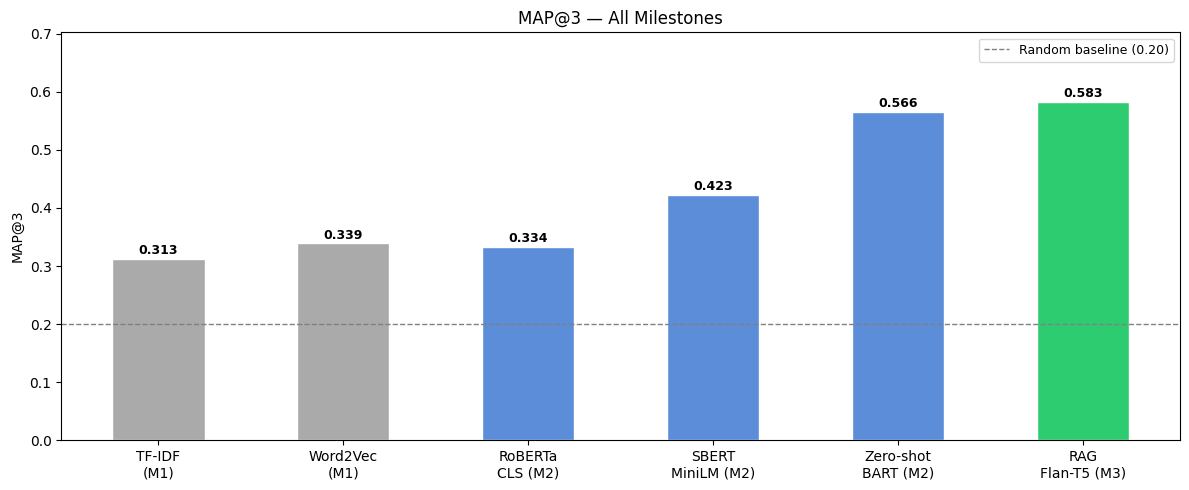

In [40]:
# ============================================================
# Bar chart — all milestones (using train_split MAP@3 for M3 RAG)
# ============================================================
labels = [
    'TF-IDF\n(M1)', 'Word2Vec\n(M1)',
    'RoBERTa\nCLS (M2)', 'SBERT\nMiniLM (M2)', 'Zero-shot\nBART (M2)',
    'RAG\nFlan-T5 (M3)'
]
scores = [map3_tfidf, map3_w2v, map3_bert, map3_sbert, map3_zs, map3_rag]
colors = ['#AAAAAA', '#AAAAAA', '#5B8DD9', '#5B8DD9', '#5B8DD9', '#2ECC71']

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(labels, scores, color=colors, width=0.5, edgecolor='white')
ax.axhline(0.2, color='gray', lw=1, ls='--', label='Random baseline (0.20)')
ax.set_ylim(0, max(scores) + 0.12)
ax.set_ylabel('MAP@3')
ax.set_title('MAP@3 — All Milestones')
ax.legend(fontsize=9)
for bar, score in zip(bars, scores):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.008,
            f'{score:.3f}', ha='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()

In [41]:
# ============================================================
# Run RAG on full test_df for submission (using same rag_top3)
# ============================================================
print("Running RAG predictions on test set...")
test_df['rag_pred'] = [
    rag_top3(row) for _, row in tqdm(test_df.iterrows(), total=len(test_df))
]

# ============================================================
# Submission — Milestone 3
# ============================================================
submission = pd.DataFrame({
    'ID':         test_df['id'],
    'Prediction': test_df['rag_pred'],
})
submission.to_csv('submission_m3.csv', index=False)
print(submission.head(10).to_string(index=False))
print(f"\n✓ submission_m3.csv saved  ({len(submission)} rows)")

Running RAG predictions on test set...


100%|██████████| 500/500 [12:31<00:00,  1.50s/it]

 ID Prediction
  1      D A C
  2      B A D
  3      A B D
  4      A C B
  5      C D A
  6      B A E
  7      E A D
  8      B D C
  9      B A C
 10      B C D

✓ submission_m3.csv saved  (500 rows)
